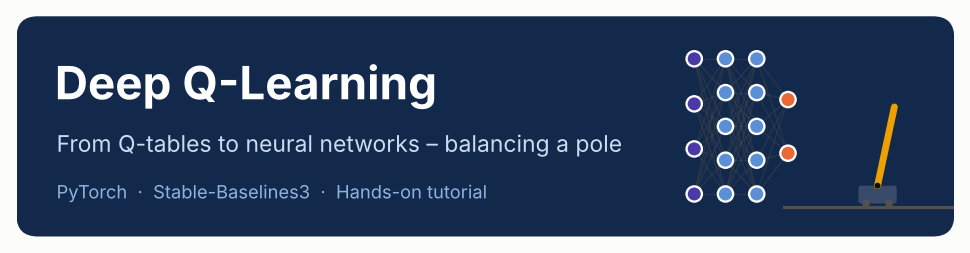

# Deep Q-Learning: from tables to neural networks

In the last notebook you trained a Q-learning agent with a **Q-table**. That works great as long as there are only a few
states — but what about a robot arm, a car or a video game? In this notebook you will

1. **build DQN (Deep Q-Network) yourself in PyTorch** — Q-learning where a neural network replaces the table, and
2. use the RL library **Stable-Baselines3** to train DQN and the popular **PPO** algorithm in a few lines of code.

Our test problem: **CartPole** — balance a pole on a moving cart. 🎢

### 🏆 Learning goals

By the end you will be able to …

1. explain **why** tabular Q-learning does not work for continuous states and what **function approximation** means,
2. explain the two key tricks of DQN: **experience replay** and the **target network**,
3. implement the building blocks of DQN in **PyTorch** (network, replay memory, ε-greedy, loss, training loop),
4. train, evaluate, save and load agents with **Stable-Baselines3**, and compare DQN with PPO,
5. interpret what a trained Q-network has learned.

### 🧭 How to read this notebook

<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**ℹ️ Blue boxes**

Background information and explanations.

</div>
<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Orange boxes — your tasks**

Replace every `...` in the code cell below the box with your own code. Hints are hidden behind **💡 Hint** – try without them first!

</div>
<div style="background:#e6f6ef; border-left:6px solid #1baf7a; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✅ Green boxes — checks**

After most tasks there is a *check cell*. Run it: it tells you if your code is correct.

</div>
<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Yellow boxes — think about it**

Short questions to discuss with your neighbour. We'll go through them together at the end.

</div>

Cells with a **title only** (🎛️ 🎮 🎬 …) are interactive widgets — just run them. Run all cells **from top to bottom**.
A GPU is **not** needed: the networks are tiny and train fastest on the CPU.

---
# Part 0 · Setup ⚙️

- `torch` (PyTorch) – neural networks and automatic differentiation
- `gymnasium` – the CartPole environment
- `stable-baselines3` – ready-to-use RL algorithms (DQN, PPO, …)
- `matplotlib`, `ipywidgets` – plots and interactive widgets

In [ ]:
#@title ⚙️ Install packages (≈ 30 s – torch is already installed in Colab)
import sys
IN_COLAB = "google.colab" in sys.modules

%pip install -q torch "gymnasium[classic-control]>=1.0" stable-baselines3 ipywidgets matplotlib tqdm pillow

if IN_COLAB:  # makes interactive widgets work in Colab
    from google.colab import output
    output.enable_custom_widget_manager()

print("✅ Setup complete –", "running in Google Colab" if IN_COLAB else "running in local Jupyter")

Now the imports for our own DQN implementation:

In [ ]:
import os
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")   # silences audio warnings of the renderer

import math
import random
from collections import namedtuple, deque

import numpy as np
import gymnasium as gym
from tqdm.auto import tqdm

import torch
import torch.nn as nn                # layers: nn.Linear, nn.Module, …
import torch.nn.functional as F      # functions: F.relu, …

The next cell contains **helper functions** for plots, widgets and checks. It is collapsed — **just run it.**

In [ ]:
#@title 🔧 Helper functions & widgets — just run this cell (no need to read or change it)
# This cell only contains plotting / checking / widget code.
# Everything that matters for Deep Q-Learning is written by YOU further below.
import warnings
# Colab's kernel (jupyter_client) emits a harmless DeprecationWarning about datetime.utcnow() every time a widget
# sends a message. It has nothing to do with this notebook – hide it so the widget outputs stay clean.
warnings.filterwarnings("ignore", message=r".*utcnow\(\) is deprecated.*", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning, module=r"jupyter_client.*")
import io
import copy
import math
import random
import threading
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.colors import LinearSegmentedColormap
import ipywidgets as widgets
import gymnasium as gym
import torch
from IPython.display import display, HTML, clear_output
from PIL import Image as PILImage

C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", red="#e34948",
         violet="#4a3aa7", ink="#0b0b0b", ink2="#52514e", grid="#e4e3df", muted="#9a9994")
CP_ACTIONS = {0: "← push left", 1: "push right →"}
# diverging map: orange = "push left" is better, grey = indifferent, blue = "push right" is better
POLICY_CMAP = LinearSegmentedColormap.from_list("policy", [C["orange"], "#f3f2ee", C["blue"]])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": C["grid"], "grid.linewidth": 0.8, "axes.edgecolor": "#b5b4ae",
                     "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"],
                     "ytick.color": C["ink2"], "axes.titleweight": "bold", "figure.dpi": 100})


# ---------------------------------------------------------------- small utilities
def _box(msg, fg, bg):
    display(HTML(f"<div style='background:{bg};border-left:6px solid {fg};padding:8px 14px;"
                 f"border-radius:6px;color:#1b1b1b;margin:4px 0'>{msg}</div>"))


def _ok(msg):   _box("✅ " + msg, C["aqua"], "#e6f6ef")
def _fail(msg): _box("❌ " + msg, C["red"], "#fdeaea")


def set_seed(seed):
    """Make random, numpy and torch reproducible (as far as possible)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


def to_tensor(observation):
    """numpy observation (4,) → float tensor of shape (1, 4) – a 'batch' with one state."""
    return torch.tensor(observation, dtype=torch.float32).unsqueeze(0)


def frame_to_png(frame, scale=1.0):
    img = PILImage.fromarray(frame)
    if scale != 1.0:
        img = img.resize((int(img.width * scale), int(img.height * scale)))
    buf = io.BytesIO()
    img.save(buf, format="png")
    return buf.getvalue()


def fig_to_png(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=90, bbox_inches="tight")
    if plt.fignum_exists(getattr(fig, "number", -1)):
        plt.close(fig)
    return buf.getvalue()


def pngs_to_gif(pngs, ms_per_frame=800):
    imgs = [PILImage.open(io.BytesIO(p)).convert("RGB") for p in pngs]
    buf = io.BytesIO()
    imgs[0].save(buf, format="gif", save_all=True, append_images=imgs[1:], duration=ms_per_frame, loop=0)
    return buf.getvalue()


def moving_average(x, w):
    x = np.asarray(x, dtype=float)
    w = max(1, min(w, len(x)))
    return np.convolve(x, np.ones(w) / w, mode="valid")


def _player(n_frames, on_frame, interval=0.8, description="step"):
    """Play/pause + step buttons + slider. Playback runs in a Python thread
    (the built-in widgets.Play / jslink do not animate reliably in Google Colab)."""
    slider = widgets.IntSlider(min=0, max=max(n_frames - 1, 0), description=description,
                               layout=widgets.Layout(width="380px"))
    play = widgets.ToggleButton(value=False, description="▶ play", layout=widgets.Layout(width="95px"))
    prev = widgets.Button(description="◀", tooltip="previous", layout=widgets.Layout(width="42px"))
    nxt = widgets.Button(description="▶", tooltip="next", layout=widgets.Layout(width="42px"))
    state = {"thread": None}

    def loop():
        try:
            if slider.value >= slider.max:
                slider.value = 0
            while play.value and slider.value < slider.max:
                time.sleep(interval(slider.value) if callable(interval) else interval)
                if play.value:
                    slider.value += 1
        finally:
            play.value = False

    def toggled(ch):
        play.description = "⏸ pause" if ch["new"] else "▶ play"
        if ch["new"] and (state["thread"] is None or not state["thread"].is_alive()):
            state["thread"] = threading.Thread(target=loop, daemon=True)
            state["thread"].start()

    play.observe(toggled, names="value")
    prev.on_click(lambda _: setattr(slider, "value", max(slider.min, slider.value - 1)))
    nxt.on_click(lambda _: setattr(slider, "value", min(slider.max, slider.value + 1)))
    slider.observe(lambda ch: on_frame(ch["new"]), names="value")
    return widgets.HBox([play, prev, nxt, slider]), slider, play


# ---------------------------------------------------------------- training history (📊 logging)
def new_history():
    return {"rewards": [], "epsilons": [], "losses": [], "steps": [], "snapshots": {}}


def log_episode(history, episode, episode_reward, epsilon, losses, steps_done, q_network):
    """Store statistics of one episode and – densely at the start, sparser later – a copy of the weights."""
    history["rewards"].append(episode_reward)
    history["epsilons"].append(epsilon)
    history["losses"].append(float(np.mean(losses)) if losses else np.nan)
    history["steps"].append(steps_done)
    if episode < 20 or episode % 5 == 0:
        history["snapshots"][episode] = copy.deepcopy(q_network.state_dict())


def is_solved(history, window=10, threshold=475):
    """CartPole counts as solved when the last `window` episodes average ≥ 475."""
    r = history["rewards"]
    return len(r) >= window and np.mean(r[-window:]) >= threshold


def plot_dqn_history(history, title="DQN training progress"):
    r = np.asarray(history["rewards"])
    w = max(5, len(r) // 20)
    fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True,
                                     gridspec_kw=dict(height_ratios=[2.2, 1, 1]))
    a1.plot(r, color=C["blue"], alpha=0.25, lw=1)
    a1.plot(np.arange(w - 1, len(r)), moving_average(r, w), color=C["blue"], lw=2.2)
    a1.axhline(500, color=C["muted"], ls="--", lw=1)
    a1.text(0, 505, "max. 500", color=C["ink2"], fontsize=9, va="bottom")
    a1.set_ylabel(f"episode reward\n(line: avg. of {w})")
    a1.set_title(title, loc="left")
    a2.plot(history["epsilons"], color=C["orange"], lw=2)
    a2.set_ylabel("ε at end\nof episode"); a2.set_ylim(0, 1)
    a3.plot(history["losses"], color=C["violet"], lw=1.5)
    a3.set_ylabel("mean loss"); a3.set_xlabel("episode")
    plt.tight_layout(); plt.show()


# ---------------------------------------------------------------- policy map / Q-network inspector
TH_MAX, THD_MAX = 0.21, 2.0       # pole angle (rad, ≈12°) and angular velocity range for the plots


def q_values(q_network, obs):
    with torch.no_grad():
        return q_network(torch.tensor(np.asarray(obs), dtype=torch.float32).reshape(-1, 4)).numpy()


def _policy_grid(q_network, x=0.0, x_dot=0.0, n=61):
    th = np.linspace(-TH_MAX, TH_MAX, n)
    thd = np.linspace(-THD_MAX, THD_MAX, n)
    T, TD = np.meshgrid(th, thd)
    obs = np.stack([np.full(T.size, x), np.full(T.size, x_dot), T.ravel(), TD.ravel()], axis=1)
    q = q_values(q_network, obs)
    return th, thd, (q[:, 1] - q[:, 0]).reshape(n, n)


def draw_policy_map(ax, q_network, x=0.0, x_dot=0.0, marker=None, title=True, colorbar=True):
    th, thd, diff = _policy_grid(q_network, x, x_dot)
    lim = max(float(np.percentile(np.abs(diff), 90)), 1e-6)     # robust colour scale
    im = ax.imshow(diff, origin="lower", extent=[np.degrees(-TH_MAX), np.degrees(TH_MAX), -THD_MAX, THD_MAX],
                   aspect="auto", cmap=POLICY_CMAP, vmin=-lim, vmax=lim)
    ax.contour(np.degrees(th), thd, diff, levels=[0], colors=C["ink"], linewidths=1.2)
    ax.grid(False)
    ax.set_xlabel("pole angle θ  [°]   (positive = leaning right)")
    ax.set_ylabel("angular velocity θ̇  [rad/s]\n(positive = falling to the right)")
    if title:
        ax.set_title("Greedy policy:  Q(s, →) − Q(s, ←)   (black line: both equal)", loc="left", fontsize=10.5)
    if colorbar:
        cb = ax.figure.colorbar(im, ax=ax, fraction=0.05, pad=0.02, ticks=[-lim, 0, lim])
        cb.ax.set_yticklabels(["← push left", "equal", "push right →"])
        cb.outline.set_visible(False)
    if marker is not None:
        ax.plot(np.degrees(marker[0]), marker[1], "o", ms=11, mfc="white", mec=C["ink"], mew=2)
    return im


def plot_policy_map(q_network, title=None):
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    draw_policy_map(ax, q_network)
    if title:
        fig.suptitle(title, x=0.02, ha="left", fontweight="bold")
    plt.tight_layout(); plt.show()


def render_state(state):
    """Render CartPole in an arbitrary state (x, x_dot, theta, theta_dot)."""
    e = gym.make("CartPole-v1", render_mode="rgb_array")
    e.reset()
    e.unwrapped.state = np.array(state, dtype=np.float64)
    frame = e.render()
    e.close()
    return frame


def q_network_inspector(q_network):
    """Sliders for the 4 state variables → Q-values, greedy action, rendering and policy map."""
    st = {"description_width": "120px"}
    lay = widgets.Layout(width="380px")
    s = dict(
        x=widgets.FloatSlider(value=0.0, min=-2.4, max=2.4, step=0.1, description="cart position x", style=st, layout=lay),
        x_dot=widgets.FloatSlider(value=0.0, min=-2, max=2, step=0.1, description="cart velocity ẋ", style=st, layout=lay),
        theta=widgets.FloatSlider(value=3.0, min=-12, max=12, step=0.5, description="pole angle θ [°]", style=st, layout=lay),
        theta_dot=widgets.FloatSlider(value=0.0, min=-2, max=2, step=0.1, description="ang. velocity θ̇", style=st, layout=lay),
    )
    img_cart = widgets.Image(format="png", width="300")
    img_map = widgets.Image(format="png", width="430")
    info = widgets.HTML()

    def update(*_):
        x, xd, th, thd = s["x"].value, s["x_dot"].value, np.radians(s["theta"].value), s["theta_dot"].value
        q = q_values(q_network, [x, xd, th, thd])[0]
        a = int(np.argmax(q))
        img_cart.value = frame_to_png(render_state([x, xd, th, thd]), scale=0.5)
        fig = Figure(figsize=(6.4, 4.0))
        ax = fig.subplots()
        draw_policy_map(ax, q_network, x, xd, marker=(th, thd), title=False)
        ax.set_title(f"policy map for x = {x:+.1f}, ẋ = {xd:+.1f}", loc="left", fontsize=10.5)
        fig.tight_layout()
        img_map.value = fig_to_png(fig)
        bar = lambda v, col: (f"<div style='display:inline-block;height:12px;width:{max(2, 140 * v / max(abs(q).max(), 1e-6)):.0f}px;"
                              f"background:{col};border-radius:3px;vertical-align:middle'></div>")
        info.value = (f"<div style='font-size:14px;line-height:1.9;color:#1b1b1b'>"
                      f"Q(s, ←) = <b>{q[0]:7.2f}</b> {bar(q[0], C['orange'])}<br>"
                      f"Q(s, →) = <b>{q[1]:7.2f}</b> {bar(q[1], C['blue'])}<br>"
                      f"greedy action: <b style='color:{C['blue'] if a else C['orange']}'>{CP_ACTIONS[a]}</b></div>")

    for w in s.values():
        w.observe(update, names="value")
    update()
    return widgets.VBox([widgets.HBox([widgets.VBox(list(s.values()) + [info]), img_cart]), img_map])


def training_snapshot_widget(history, q_network):
    """Watch the policy map change during training, next to the learning curve."""
    eps = sorted(history["snapshots"])
    rewards = np.asarray(history["rewards"])
    net = copy.deepcopy(q_network)
    img = widgets.Image(format="png", width="900")
    gif = widgets.Image(format="gif", width="900", layout=widgets.Layout(display="none"))
    cache = {}

    def render(k):
        if k not in cache:
            ep = eps[k]
            net.load_state_dict(history["snapshots"][ep])
            fig = Figure(figsize=(11, 4.2))
            a1, a2 = fig.subplots(1, 2, gridspec_kw=dict(width_ratios=[1, 1.15]))
            draw_policy_map(a1, net)
            a2.plot(rewards, color=C["grid"], lw=1)
            a2.plot(np.arange(ep + 1), rewards[:ep + 1], color=C["blue"], lw=1.5)
            a2.plot(ep, rewards[ep], "o", color=C["blue"], ms=7)
            a2.set_ylim(0, 520); a2.set_xlabel("episode"); a2.set_ylabel("episode reward")
            a2.set_title("Learning curve", loc="left", fontsize=11)
            fig.suptitle(f"after episode {ep + 1}   (ε = {history['epsilons'][ep]:.2f},  reward = {rewards[ep]:.0f})",
                         x=0.02, ha="left", fontweight="bold")
            fig.tight_layout()
            cache[k] = fig_to_png(fig)
        return cache[k]

    def show(k):
        img.value = render(k)

    controls, slider, play = _player(len(eps), show, interval=0.9, description="snapshot")

    def as_gif(_):
        play.value = False
        btn.disabled = True
        for k in range(len(eps)):
            btn.description = f"rendering {k + 1}/{len(eps)} …"
            render(k)
        gif.value = pngs_to_gif([cache[k] for k in range(len(eps))], 500)
        img.layout.display, gif.layout.display = "none", None
        btn.description, btn.disabled = "as GIF", False

    btn = widgets.Button(description="as GIF", icon="film", tooltip="whole training as animated GIF")
    btn.on_click(as_gif)
    slider.observe(lambda _: (setattr(img.layout, "display", None), setattr(gif.layout, "display", "none")),
                   names="value")
    show(0)
    return widgets.VBox([controls, btn, img, gif])


# ---------------------------------------------------------------- playing / replays
def play_cartpole():
    """Balance the pole yourself: every click = one time step."""
    penv = gym.make("CartPole-v1", render_mode="rgb_array")
    st = {}
    img = widgets.Image(format="png", width="360")
    status = widgets.HTML()

    def refresh():
        img.value = frame_to_png(penv.render(), scale=0.6)
        o = st["obs"]
        msg = (f"<div style='font-family:monospace;font-size:13px;line-height:1.7;color:#1b1b1b'>"
               f"x = {o[0]:+.3f} &nbsp; ẋ = {o[1]:+.3f}<br>θ = {o[2]:+.3f} rad ({np.degrees(o[2]):+.1f}°) &nbsp; "
               f"θ̇ = {o[3]:+.3f}</div>steps survived: <b>{st['steps']}</b> &nbsp;|&nbsp; total reward <b>{st['reward']:g}</b>")
        if st["done"]:
            msg += " &nbsp; 💥 <b style='color:#e34948'>pole fell / cart left the track</b> → reset"
        status.value = msg

    def reset(_=None):
        o, _ = penv.reset()
        st.update(obs=o, steps=0, reward=0.0, done=False)
        refresh()

    def step(a):
        if st["done"]:
            return
        o, r, te, tr, _ = penv.step(a)
        st.update(obs=o, steps=st["steps"] + 1, reward=st["reward"] + r, done=te or tr)
        refresh()

    bl = widgets.Button(description="← push left", layout=widgets.Layout(width="130px"))
    br = widgets.Button(description="push right →", layout=widgets.Layout(width="130px"))
    rs = widgets.Button(description="reset", icon="refresh", button_style="warning")
    bl.on_click(lambda _: step(0)); br.on_click(lambda _: step(1)); rs.on_click(reset)
    reset()
    return widgets.HBox([img, widgets.VBox([status, widgets.HBox([bl, br]), rs],
                                           layout=widgets.Layout(margin="0 0 0 16px"))])


def dqn_policy(q_network):
    """Greedy policy of a Q-network as a function obs → action."""
    return lambda obs: int(np.argmax(q_values(q_network, obs)[0]))


def sb3_policy(model):
    """Policy of a Stable-Baselines3 model as a function obs → action."""
    return lambda obs: int(model.predict(obs, deterministic=True)[0])


def rollout(policy, seed=None, max_steps=500):
    e = gym.make("CartPole-v1", render_mode="rgb_array")
    obs, _ = e.reset(seed=seed if seed is not None else random.randint(0, 10_000))
    frames, total = [e.render()], 0.0
    for _ in range(max_steps):
        obs, r, te, tr, _ = e.step(policy(obs))
        total += r
        frames.append(e.render())
        if te or tr:
            break
    e.close()
    return frames, total


def replay_widget(policy, every=2):
    """Watch an agent: ▶ play / ◀ ▶ / slider, or as animated GIF. Shows every `every`-th frame."""
    img = widgets.Image(format="png", width="420")
    gif = widgets.Image(format="gif", width="420", layout=widgets.Layout(display="none"))
    info = widgets.HTML()
    data = {}

    def show(k):
        img.value = data["pngs"][k]
        info.value = f"time step <b>{min(k * every, data['total']):.0f}</b> of <b>{data['total']:.0f}</b>"

    controls, slider, play = _player(1, show, interval=0.06, description="frame")

    def new_episode(_=None):
        play.value = False
        frames, total = rollout(policy)
        frames = frames[::every]
        data.update(pngs=[frame_to_png(f, scale=0.7) for f in frames], total=total)
        gif.layout.display, img.layout.display = "none", None
        slider.max = len(frames) - 1
        if slider.value == 0:
            show(0)
        else:
            slider.value = 0

    def as_gif(_):
        gif.value = pngs_to_gif(data["pngs"], 40 * every)
        img.layout.display, gif.layout.display = "none", None

    b1 = widgets.Button(description="new episode", icon="refresh"); b1.on_click(new_episode)
    b2 = widgets.Button(description="as GIF", icon="film"); b2.on_click(as_gif)
    new_episode()
    return widgets.VBox([img, gif, controls, widgets.HBox([b1, b2]), info])


# ---------------------------------------------------------------- Stable-Baselines3 log plots
def plot_sb3_logs(logs, title="Stable-Baselines3: evaluation reward during training"):
    """logs = {"label": dataframe from pd.read_csv(...)} – one line per run, same axes.
    Plots eval/mean_reward (greedy agent, measured by EvalCallback every 5 000 steps)."""
    colors = [C["blue"], C["orange"], C["aqua"], C["violet"]]
    fig, ax = plt.subplots(figsize=(9, 4.2))
    for (label, df), col in zip(logs.items(), colors):
        key = "eval/mean_reward" if "eval/mean_reward" in df else "rollout/ep_rew_mean"
        d = df.dropna(subset=[key])
        ax.plot(d["time/total_timesteps"], d[key], color=col, lw=2, marker="o", ms=5, label=label)
    ax.axhline(500, color=C["muted"], ls="--", lw=1)
    ax.set_ylim(0, 540)
    ax.set_xlabel("environment time steps"); ax.set_ylabel("evaluation reward\n(greedy, 5 episodes)")
    ax.set_title(title, loc="left", pad=28)
    ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=len(logs), fontsize=9.5)
    ax.text(0, -0.3, "Each point: the greedy agent (no exploration) evaluated on 5 episodes. Single runs are noisy – "
            "a dip does not mean the algorithm failed.", transform=ax.transAxes, fontsize=9, color=C["ink2"])
    plt.tight_layout(); plt.show()


def results_table(rows):
    """rows = list of (name, mean reward, std, time steps used for training)."""
    body = "".join(f"<tr><td style='padding:3px 12px'>{n}</td><td style='padding:3px 12px;text-align:right'><b>{m:.1f}</b> ± {s:.1f}</td>"
                   f"<td style='padding:3px 12px;text-align:right'>{t:,}</td></tr>" for n, m, s, t in rows)
    display(HTML("<table style='border-collapse:collapse'><tr><th style='padding:3px 12px'>agent</th>"
                 "<th style='padding:3px 12px'>evaluation reward</th><th style='padding:3px 12px'>training time steps</th></tr>"
                 + body + "</table>"))


# ---------------------------------------------------------------- DQN lab
def dqn_lab(train_fn, evaluate_fn):
    """Train your own DQN with chosen hyperparameters; keeps a table of all runs."""
    st = {"description_width": "130px"}
    lay = widgets.Layout(width="400px")
    w = dict(
        n_episodes=widgets.Dropdown(options=[50, 100, 150, 200, 300], value=150, description="episodes", style=st, layout=lay),
        lr=widgets.FloatLogSlider(value=1e-3, base=10, min=-5, max=-1, step=0.25, readout_format=".0e",
                                  description="learning rate", style=st, layout=lay),
        tau=widgets.FloatLogSlider(value=0.01, base=10, min=-4, max=0, step=0.25, readout_format=".4f",
                                   description="τ (target update)", style=st, layout=lay),
        memory_capacity=widgets.Dropdown(options=[128, 1000, 10000, 50000], value=10000,
                                         description="replay capacity", style=st, layout=lay),
        n_hidden=widgets.Dropdown(options=[16, 32, 64, 128, 256], value=128, description="hidden neurons", style=st, layout=lay),
        eps_decay=widgets.Dropdown(options=[100, 1000, 5000, 20000], value=1000, description="ε decay (steps)", style=st, layout=lay),
    )
    btn = widgets.Button(description="Train & evaluate", button_style="success", icon="play",
                         layout=widgets.Layout(width="200px"))
    out, table = widgets.Output(), widgets.HTML()
    runs = []

    def run(_):
        btn.disabled = True
        with out:
            clear_output(wait=True)
            try:
                lab_env = gym.make("CartPole-v1")
                t0 = time.time()
                net, hist = train_fn(lab_env, seed=0, **{k: v.value for k, v in w.items()})
                mean, std = evaluate_fn(net, lab_env, 10)
                plot_dqn_history(hist, title="Lab run: training progress")
                (_ok if mean >= 475 else _fail)(f"evaluation reward <b>{mean:.1f} ± {std:.1f}</b> "
                                                f"after {len(hist['rewards'])} episodes ({time.time() - t0:.0f} s)")
                runs.append(dict(**{k: v.value for k, v in w.items()}, episodes_run=len(hist["rewards"]), mean=mean))
                head = "".join(f"<th style='padding:2px 8px'>{k}</th>" for k in runs[0])
                rows = "".join("<tr>" + "".join(f"<td style='padding:2px 8px'>{v:.4g}</td>" if isinstance(v, float)
                                               else f"<td style='padding:2px 8px'>{v}</td>" for v in r.values()) + "</tr>"
                               for r in runs)
                table.value = f"<b>Your runs</b><table style='border-collapse:collapse'><tr>{head}</tr>{rows}</table>"
            except Exception as e:
                _fail(f"Training failed: <code>{e!r}</code> – are all your functions above complete?")
        btn.disabled = False

    btn.on_click(run)
    keys = list(w)
    return widgets.VBox([widgets.HBox([widgets.VBox([w[k] for k in keys[:3]]), widgets.VBox([w[k] for k in keys[3:]])]),
                         btn, table, out])


# ---------------------------------------------------------------- automatic checks
def _is_missing(x):
    return x is None or x is Ellipsis


def check_qnetwork(cls):
    try:
        net = cls(4, 2, 64)
        if _is_missing(getattr(net, "layer3", None)):
            return _fail("<code>self.layer3</code> is still missing – did you replace the <code>...</code>?")
        out = net(torch.zeros(5, 4))
        if tuple(out.shape) != (5, 2):
            return _fail(f"For a batch of 5 states the output should have shape (5, 2) – one Q-value per action – got {tuple(out.shape)}.")
        out3 = cls(8, 3, 16)(torch.zeros(7, 8))
        if tuple(out3.shape) != (7, 3):
            return _fail("Works for CartPole but not for other sizes – use <code>n_hidden</code> and <code>n_actions</code>, don't hard-code numbers.")
    except Exception as e:
        return _fail(f"Your network raised an error: <code>{e!r}</code> – check the input/output sizes of <code>nn.Linear</code>.")
    _ok("Q-network: input 4 numbers → output one Q-value per action.")


def check_replay_memory(cls):
    try:
        m = cls(5)
        for i in range(8):
            m.push(np.full(4, float(i)), 0, 1.0, np.zeros(4), False)
        if len(m) != 5:
            return _fail(f"After pushing 8 transitions into a memory of capacity 5, its length should be 5, got {len(m)}.")
        batch = m.sample(3)
        if _is_missing(batch):
            return _fail("<code>sample</code> returns nothing yet – did you replace the <code>...</code>?")
        if len(batch) != 3 or not all(isinstance(t, Transition) for t in batch):
            return _fail("<code>sample(3)</code> should return a list of 3 <code>Transition</code>s.")
        vals = sorted(float(t.state[0]) for t in batch)
        if len(set(vals)) != 3 or min(vals) < 3:
            return _fail("Samples should be 3 <b>different</b> transitions from the memory (the oldest ones were dropped). "
                         "Hint: <code>random.sample</code> samples without replacement.")
    except Exception as e:
        return _fail(f"Your replay memory raised an error: <code>{e!r}</code>")
    _ok("Replay memory stores, forgets the oldest and samples random minibatches.")


class _FixedNet(torch.nn.Module):
    """Fake 'network' that always returns the same Q-values."""
    def __init__(self, q):
        super().__init__()
        self.q = torch.tensor(q, dtype=torch.float32)

    def forward(self, x):
        return self.q.clone() if x.dim() == 1 else self.q.repeat(x.shape[0], 1)


def check_select_action(fn):
    net = _FixedNet([0.1, 0.9])
    s = np.zeros(4, dtype=np.float32)
    random.seed(0); np.random.seed(0); torch.manual_seed(0)
    try:
        a0 = [fn(net, s, 0.0, 2) for _ in range(100)]
        if any(_is_missing(a) for a in a0):
            return _fail("The function returns nothing yet – did you replace all <code>...</code>?")
        if any(not isinstance(a, (int, np.integer)) for a in a0):
            return _fail(f"The action must be a plain Python <code>int</code>, got <code>{type(a0[0]).__name__}</code>. "
                         "Hint: <code>int(q_values.argmax())</code>.")
        if any(a != 1 for a in a0):
            return _fail("With ε = 0 the agent must always pick the action with the highest Q-value (here: 1).")
        a1 = [fn(net, s, 1.0, 2) for _ in range(2000)]
        if not 0.4 < np.mean(a1) < 0.6:
            return _fail(f"With ε = 1 both actions should be chosen ≈ 50 % of the time, got {np.mean(a1):.0%} for action 1.")
        a5 = np.mean([fn(net, s, 0.5, 2) for _ in range(2000)])
        if not 0.68 < a5 < 0.82:
            return _fail(f"With ε = 0.5 action 1 should be chosen ≈ 75 % of the time, got {a5:.0%}. Is the comparison the right way round?")
    except Exception as e:
        return _fail(f"Your function raised an error: <code>{e!r}</code>")
    _ok("ε-greedy action selection works for ε = 0, 0.5 and 1.")


def _reference_loss(q_network, target_net, transitions, gamma):
    with torch.no_grad():
        q_pred, target = [], []
        for t in transitions:
            q_pred.append(q_network(torch.tensor(t.state, dtype=torch.float32))[t.action])
            future = 0.0 if t.terminated else target_net(torch.tensor(t.next_state, dtype=torch.float32)).max()
            target.append(t.reward + gamma * future)
        return torch.nn.functional.smooth_l1_loss(torch.stack(q_pred), torch.tensor(target, dtype=torch.float32)).item()


class _Mem:
    """Minimal reference replay memory, so that this check does not depend on Task 3."""
    def __init__(self):
        self.memory = []
    def push(self, *args):
        self.memory.append(Transition(*args))
    def sample(self, k):
        return [self.memory[i] for i in np.random.choice(len(self.memory), k, replace=False)]
    def __len__(self):
        return len(self.memory)


def check_optimize_model(fn, net_cls):
    set_seed(1)
    try:
        q, t = net_cls(4, 2, 16), net_cls(4, 2, 16)     # different random weights on purpose
        q(torch.zeros(1, 4))
    except Exception:
        return _fail("Complete the Q-network (Task 2) first.")
    mem = _Mem()
    for i in range(8):
        mem.push(np.random.randn(4).astype(np.float32), i % 2, 1.0, np.random.randn(4).astype(np.float32), i in (2, 5))
    ref = _reference_loss(q, t, list(mem.memory), 0.9)
    t_before = copy.deepcopy(t.state_dict())
    q_before = copy.deepcopy(q.state_dict())
    opt = torch.optim.SGD(q.parameters(), lr=0.01)
    try:
        loss = fn(q, t, mem, opt, batch_size=8, gamma=0.9)
    except Exception as e:
        return _fail(f"<code>optimize_model</code> raised an error: <code>{e!r}</code>")
    if _is_missing(loss):
        return _fail("The function returns nothing – did you replace all <code>...</code>?")
    if abs(loss - ref) > 1e-4:
        hint = ("Do you use the <b>Q-network</b> in (a), the <b>target network</b> in (b), and "
                "<code>rewards + gamma * next_q_max * (1 - terminated)</code> in (c)?")
        return _fail(f"Loss = {loss:.5f}, expected {ref:.5f}. {hint}")
    if not all(torch.equal(t_before[k], v) for k, v in t.state_dict().items()):
        return _fail("The target network was changed by the gradient step – compute its values inside <code>torch.no_grad()</code>.")
    if all(torch.equal(q_before[k], v) for k, v in q.state_dict().items()):
        return _fail("The Q-network weights did not change – is the optimizer step still executed?")
    _ok("optimize_model computes the correct DQN loss (incl. terminal states) and updates only the Q-network.")


def check_train_dqn(fn):
    try:
        e = gym.make("CartPole-v1")
        net, hist = fn(e, n_episodes=4, seed=0, batch_size=16)
    except Exception as ex:
        return _fail(f"Training raised an error: <code>{ex!r}</code> – check the lines with <code>...</code>.")
    if len(hist["rewards"]) != 4 or hist["steps"][-1] < 4:
        return _fail("Something is off: 4 episodes should be logged.")
    if hist["steps"][-1] != sum(hist["rewards"]):
        return _fail("The number of steps should equal the summed rewards (+1 per step) – is <code>episode_reward</code> updated?")
    _ok(f"Training loop runs (4 test episodes, {hist['steps'][-1]} steps). Now train for real!")


print(f"✅ Helpers loaded  (gymnasium {gym.__version__}, torch {torch.__version__}, ipywidgets {widgets.__version__})")

---
# Part 1 · The big picture 🧠

## 1.1 Why a Q-table is not enough

In FrozenLake the state was **one integer** (0 … 15), so the Q-table had 16 rows. In CartPole the state consists of
**four real numbers** — positions, angles and velocities. There are infinitely many different states; we will never
see exactly the same state twice. A table is impossible.

**Idea:** replace the table by a **function** $Q(s, a; \theta)$ with parameters $\theta$ — a small **neural network**.
It takes the state as input and outputs **one Q-value per action**. Because similar states produce similar outputs,
the network **generalises**: what it learned in one state also helps in similar states it has never seen.


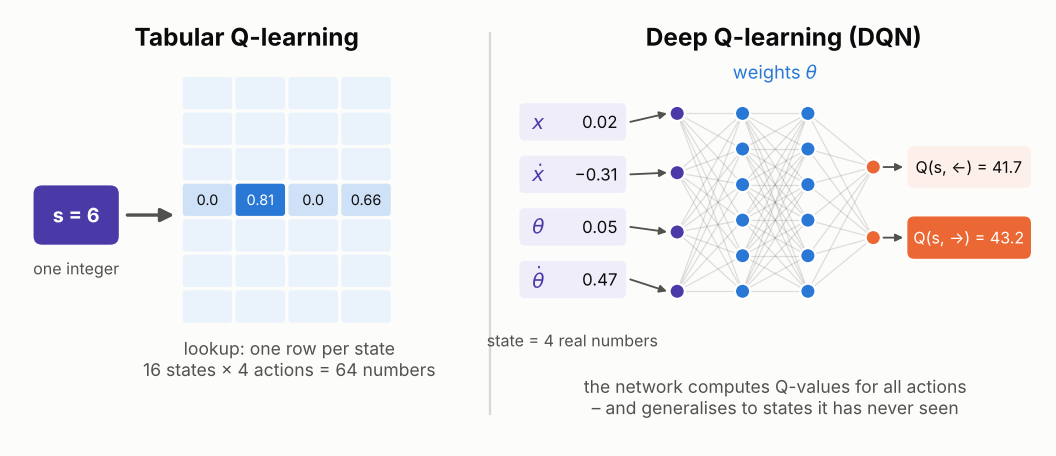

This is called **function approximation**; with a deep neural network the algorithm is called **Deep Q-Network (DQN)**
([Mnih et al., 2013](https://arxiv.org/abs/1312.5602)) — the algorithm that learned to play Atari games from pixels.

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Think about it (Q1)**

Couldn't we simply **cut** each of the four state variables into, say, 10 bins and use a Q-table with $10^4$ rows after all?
What would be the problems — for CartPole, and for an agent that sees camera images?

</div>

## 1.2 The CartPole environment

A pole is attached to a cart that moves along a track. The agent can **push the cart left or right**. Goal: keep the pole
upright as long as possible.


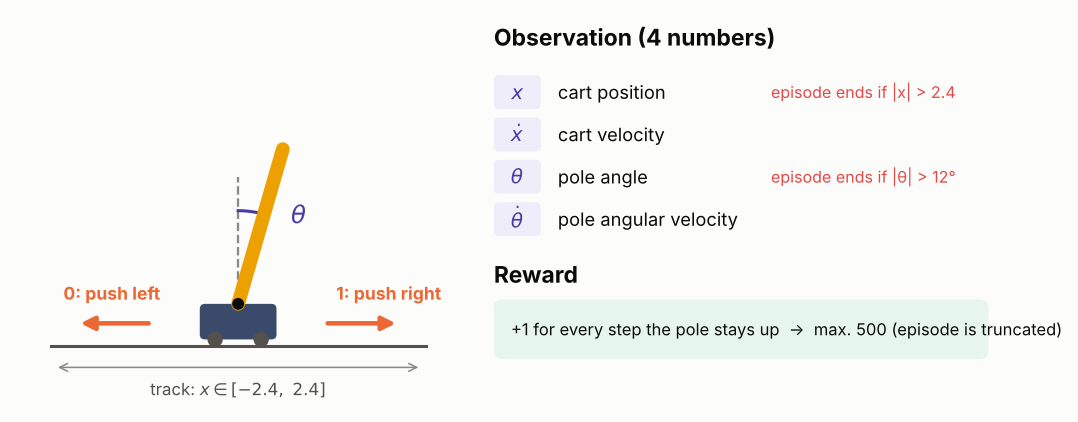

The episode **terminates** when the pole tilts more than 12° or the cart leaves the track, and is **truncated** after 500 steps.
A perfect agent therefore gets a reward of **500**.


<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 1 — create the environment**

Create the `"CartPole-v1"` environment and store it in `env`. Then run the cell to look at the observation and action space.

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

`gym.make("<environment name>")` — like last time.

</details>

In [ ]:
env = ...  # YOUR CODE HERE

print("Observation space:", env.observation_space)
print("Action space:     ", env.action_space)
state, info = env.reset(seed=0)
print("A start state:    ", state)

`Box(4,)` means: a vector of **4 real numbers** (instead of `Discrete(16)` in FrozenLake). `Discrete(2)`: two actions,
0 = push left, 1 = push right.


<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🎮 Widget: balance the pole yourself!**

Every click is **one time step** (the pole does not fall while you think). How many steps can you survive?
Watch how the four numbers change. Which ones are dangerous?

</div>

In [ ]:
#@title 🎮 Widget: play CartPole — run this cell
display(play_cartpole())

## 1.3 DQN = Q-learning + neural network + two tricks

Simply plugging a neural network into Q-learning is notoriously **unstable**. DQN adds two tricks:


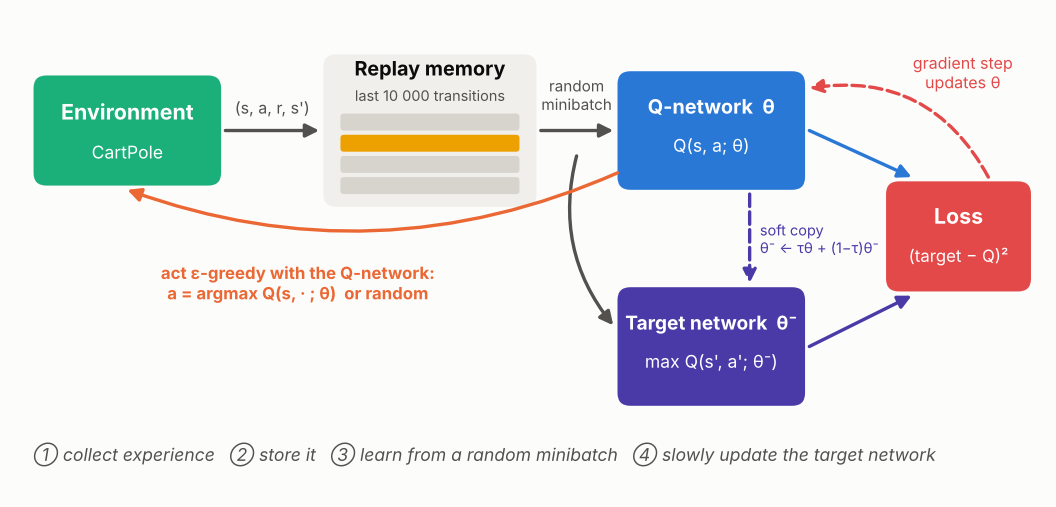

| Trick | What | Why |
|:--|:--|:--|
| **Experience replay** | Every transition $(s, a, r, s')$ is stored in a **replay memory**. The network learns from **random minibatches** of old transitions. | Consecutive steps are highly correlated (the pole at $t$ and $t+1$ looks almost the same). Random samples make the training data more i.i.d. — like shuffling a dataset — and every experience can be reused many times. |
| **Target network** | A second, slowly updated copy of the network ($\theta^-$) computes the TD target. | Otherwise the target $r + \gamma \max Q(s',a')$ would change with every gradient step — we would be chasing a **moving target**. |

## 1.4 The loss: Q-learning as supervised learning

Instead of updating a table entry, DQN performs a **gradient descent step** on a loss — exactly like in supervised learning,
except that the "labels" (the TD targets) are produced by the agent itself:


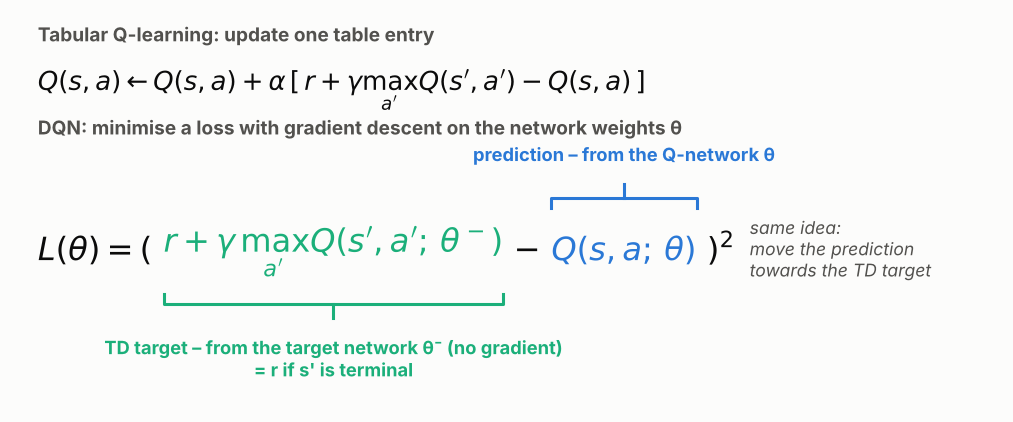

In practice the squared error is replaced by the **Huber loss** (`SmoothL1Loss`): quadratic for small errors, linear for large
ones, so single outliers can't produce huge gradients.

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Think about it (Q2 & Q3)**

**Q2.** Why do we learn from **random** old transitions instead of simply from the **last** step, as in tabular Q-learning?

**Q3.** What could go wrong if the TD target were computed with the **same** network that we are updating?

</div>

## 1.5 The algorithm and your tasks

<div style="background:#f7f7f5; border-radius:8px; padding:12px 20px; font-family:monospace; color:#1b1b1b; line-height:1.7">
<b>Initialise</b> Q-network θ with random weights &nbsp; <span style="color:#eb6834">← ✏️ Task 2</span>, target network θ⁻ ← θ<br>
<b>Initialise</b> replay memory D &nbsp; <span style="color:#eb6834">← ✏️ Task 3</span><br>
<b>for</b> episode = 1 … M: &nbsp; <span style="color:#eb6834">← ✏️ Task 6</span><br>
&nbsp;&nbsp;&nbsp;&nbsp;s ← reset environment<br>
&nbsp;&nbsp;&nbsp;&nbsp;<b>repeat</b> until the episode ends:<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;a ← ε-greedy w.r.t. Q(s, · ; θ) &nbsp; <span style="color:#eb6834">← ✏️ Task 4</span><br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;execute a, observe r, s' &nbsp;and store (s, a, r, s') in D<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;sample a random minibatch from D and do one gradient step on the loss &nbsp; <span style="color:#eb6834">← ✏️ Task 5</span><br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;θ⁻ ← τθ + (1−τ)θ⁻<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;s ← s'<br>
</div>

Compare it with the Q-learning algorithm from last time: the loop is the same — only the table update was replaced.

---
# Part 2 · DQN from scratch in PyTorch 🔥

## 2.1 PyTorch in two minutes


<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**ℹ️ The four PyTorch concepts you need**

1. **Tensors** are PyTorch's arrays (like NumPy arrays, but they can track gradients). Networks always process a **batch** of inputs:
   one CartPole state has shape `(4,)`, a minibatch of 128 states has shape `(128, 4)` — the same network handles both.
2. **Layers** like `nn.Linear(in_features, out_features)` compute $y = Wx + b$ with learnable $W, b$.
3. A **network** is a class derived from `nn.Module`: layers are created in `__init__`, the computation is written in `forward`.
   Calling `net(x)` runs `forward(x)`.
4. **Training step:** `loss.backward()` computes the gradients of the loss w.r.t. all weights (autograd), `optimizer.step()` changes
   the weights a little bit against the gradient, `optimizer.zero_grad()` clears the old gradients first.

</div>

In [ ]:
# A tiny demo – just run it
x = torch.tensor([[0.02, -0.31, 0.05, 0.47]])    # one state, shape (1, 4)
layer = nn.Linear(4, 2)                            # 4 inputs → 2 outputs (random weights)
y = layer(x)
print("input shape :", tuple(x.shape))
print("output      :", y, " shape", tuple(y.shape))
print("argmax      :", y.argmax(dim=1).item(), "← index of the largest output = greedy action")

## 2.2 The Q-network 🧠

Our network has two hidden layers with ReLU activation and an **output layer with one neuron per action**:

$$\underbrace{4}_{\text{state}} \;\to\; 128 \;\xrightarrow{\text{ReLU}}\; 128 \;\xrightarrow{\text{ReLU}}\; \underbrace{2}_{Q(s,\leftarrow),\; Q(s,\rightarrow)}$$


<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 2 — complete the Q-network**

Add the third (output) layer `self.layer3`. Which sizes do its input and output need?

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

The output layer takes the `n_hidden` outputs of `layer2` and must produce **one value per action**: `nn.Linear(?, ?)`.

</details>

In [ ]:
class QNetwork(nn.Module):

    def __init__(self, n_observations, n_actions, n_hidden):
        super().__init__()
        self.layer1 = nn.Linear(n_observations, n_hidden)
        self.layer2 = nn.Linear(n_hidden, n_hidden)
        self.layer3 = ...  # YOUR CODE HERE: the output layer

    def forward(self, x):
        x = F.relu(self.layer1(x))
        x = F.relu(self.layer2(x))
        return self.layer3(x)       # no activation: Q-values can be any real number

In [ ]:
check_qnetwork(QNetwork)

Let's create an (untrained) network and ask it for Q-values:

In [ ]:
net = QNetwork(n_observations=4, n_actions=2, n_hidden=128)
n_params = sum(p.numel() for p in net.parameters())
print(f"The network has {n_params:,} parameters – no matter how many states there are.")

state_tensor = torch.tensor(state, dtype=torch.float32)   # numpy array → tensor, shape (4,)
print("Q-values of the start state:", net(state_tensor))

## 2.3 The replay memory 🗃️

Each step of experience is stored as a small **named tuple**
`Transition(state, action, reward, next_state, terminated)` — plain NumPy arrays and Python numbers, nothing special.
The memory is a `deque` with a maximum length: when it is full, the **oldest** transition is dropped automatically.


<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 3 — complete the replay memory**

1. `push`: append a new `Transition(...)` to `self.memory`.
2. `sample`: return `batch_size` **different** random transitions.

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

- `self.memory.append(...)`
- [`random.sample(population, k)`](https://docs.python.org/3/library/random.html#random.sample) draws `k` elements without replacement.

</details>

In [ ]:
Transition = namedtuple("Transition", ("state", "action", "reward", "next_state", "terminated"))


class ReplayMemory:

    def __init__(self, capacity):
        self.memory = deque([], maxlen=capacity)   # oldest entries are dropped automatically

    def push(self, state, action, reward, next_state, terminated):
        """Save one transition."""
        ...  # YOUR CODE HERE

    def sample(self, batch_size):
        """Return a list of batch_size random transitions."""
        return ...  # YOUR CODE HERE

    def __len__(self):
        return len(self.memory)

In [ ]:
check_replay_memory(ReplayMemory)

## 2.4 ε-greedy action selection 🎲

The same idea as last time: with probability ε a random action, otherwise the action with the highest Q-value.
Two PyTorch details:

- The network needs a **tensor**, the environment gives us a NumPy array → `torch.tensor(state, dtype=torch.float32)`.
- For **acting** we don't need gradients → wrap the network call in `with torch.no_grad():` (faster, less memory).


<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 4 — select an action**

Complete `select_action`. It gets the state as a NumPy array and must return the action as a plain Python `int`.

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

- The network outputs a tensor with 2 Q-values. `q_values.argmax()` gives the index of the larger one, `int(...)` turns it into a Python number.
- Random action: `random.randrange(n_actions)`

</details>

In [ ]:
def select_action(q_network, state, epsilon, n_actions):
    if ...:  # YOUR CODE HERE: when do we exploit?
        # exploitation: greedy action of the Q-network (no gradients needed for acting)
        with torch.no_grad():
            q_values = q_network(torch.tensor(state, dtype=torch.float32))   # tensor with 2 values
        action = ...  # YOUR CODE HERE
    else:
        # exploration: random action
        action = ...  # YOUR CODE HERE
    return action

In [ ]:
check_select_action(select_action)

## 2.5 One learning step: `optimize_model` 📉

This is the heart of DQN. It does exactly what the loss figure in 1.4 says — just for a **minibatch** of 128 transitions at once:

1. Sample 128 transitions and stack them into tensors (one row per transition).
2. **Prediction** $Q(s, a; \theta)$: the network outputs **both** Q-values for every state; we keep the one of the action that was taken.
3. **TD target** $y = r + \gamma \max_{a'} Q(s', a'; \theta^-)$ — computed with the **target network**.
   If the pole fell (`terminated`), there is no future: $y = r$.
4. Loss between prediction and target → one gradient step.


<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**ℹ️ Picking “the Q-value of the action taken”**

`q_values` has one row per transition and one column per action. For every row `i` we take the column `actions[i]`:

```
q_values = [[1.2, 3.4],      actions = [1, 0, 1]   →   q_pred = [3.4,
            [0.7, 0.1],                                          0.7,
            [2.0, 2.5]]                                          2.5]
```

</div>

<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 5 — compute Q-values and TD target**

Replace the three `...` (a), (b), (c). The check below compares your loss with a reference implementation.

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

- (a) Feed the whole batch of states through the **Q-network** – exactly like a single state.
- (b) Feed `next_states` through the **target network**; `.max(dim=1).values` gives the largest value of every row.
- (c) $r + \gamma \cdot \max Q(s', \cdot)$, but the future part must vanish when `terminated` is 1 → multiply it by `(1 - terminated)`.

</details>

In [ ]:
def optimize_model(q_network, target_net, memory, optimizer, batch_size, gamma):
    if len(memory) < batch_size:          # not enough experience yet
        return None
    transitions = memory.sample(batch_size)

    # 1) stack the transitions into tensors – one row per transition
    states      = torch.tensor(np.array([t.state for t in transitions]), dtype=torch.float32)       # (B, 4)
    actions     = torch.tensor([t.action for t in transitions])                                     # (B,)
    rewards     = torch.tensor([t.reward for t in transitions], dtype=torch.float32)                # (B,)
    next_states = torch.tensor(np.array([t.next_state for t in transitions]), dtype=torch.float32)  # (B, 4)
    terminated  = torch.tensor([t.terminated for t in transitions], dtype=torch.float32)            # (B,) 1.0 = pole fell

    # 2) prediction Q(s, a; θ)
    q_values = ...  # (a) YOUR CODE HERE – shape (B, 2): Q(s,←), Q(s,→) for every state
    q_pred = torch.stack([q_values[i, actions[i]] for i in range(batch_size)])   # keep the Q-value of the action taken

    # 3) TD target  y = r + γ · max_a' Q(s', a'; θ⁻)   (no future if terminated)
    with torch.no_grad():                                          # the target is a fixed "label": no gradients
        next_q_max = ...  # (b) YOUR CODE HERE – shape (B,)
    td_target = ...  # (c) YOUR CODE HERE

    # 4) Huber loss between prediction and target, then one gradient step
    loss = F.smooth_l1_loss(q_pred, td_target)
    optimizer.zero_grad()      # forget old gradients
    loss.backward()            # compute new gradients
    optimizer.step()           # update the weights θ
    return loss.item()

In [ ]:
check_optimize_model(optimize_model, QNetwork)

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Think about it (Q4)**

**Q4.** We store `terminated` (pole fell) and cut off the future value only then — **not** when the episode is **truncated**
after 500 steps. Why does this distinction matter?

</div>

The **soft update** of the target network is given. It moves every weight of θ⁻ a tiny step (τ = 1 %) towards θ:

In [ ]:
def soft_update(target_net, q_network, tau):
    """θ⁻ ← τ·θ + (1 − τ)·θ⁻   (for every weight tensor)"""
    with torch.no_grad():
        for target_param, param in zip(target_net.parameters(), q_network.parameters()):
            target_param.copy_(tau * param + (1 - tau) * target_param)

## 2.6 The training loop 🔁

Now we put everything together. The exploration rate decays **per time step** (not per episode):

$$\varepsilon = \varepsilon_{end} + (\varepsilon_{start} - \varepsilon_{end}) \cdot e^{-\text{steps\_done} / \text{eps\_decay}}$$

Training stops early as soon as **the task is solved**: CartPole counts as solved when the average reward of the last 10 episodes is ≥ 475.


<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 6 — complete the training loop**

Replace the four `...` in the inner loop:
- **(a)** choose an action with your `select_action`
- **(b)** perform it in the environment
- **(c)** store the transition in the replay memory
- **(d)** do one learning step with `optimize_model`

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

All functions you need were written above. Look at their signatures, e.g. `select_action(q_network, state, epsilon, n_actions)`
and `memory.push(state, action, reward, next_state, terminated)`.

</details>

In [ ]:
def train_dqn(env, n_episodes=300, lr=1e-3, gamma=0.99, batch_size=128, n_hidden=128,
              eps_start=0.9, eps_end=0.05, eps_decay=1000, tau=0.01, memory_capacity=10_000, seed=None):
    if seed is not None:
        set_seed(seed)
    n_actions = env.action_space.n
    n_observations = env.observation_space.shape[0]

    q_network = QNetwork(n_observations, n_actions, n_hidden)
    target_net = QNetwork(n_observations, n_actions, n_hidden)
    target_net.load_state_dict(q_network.state_dict())          # start with identical weights
    optimizer = torch.optim.AdamW(q_network.parameters(), lr=lr, amsgrad=True)
    memory = ReplayMemory(memory_capacity)

    history = new_history()                                      # 📊
    steps_done = 0
    progress = tqdm(range(n_episodes))
    for episode in progress:
        state, info = env.reset(seed=None if seed is None else seed + episode)
        episode_reward, losses = 0, []

        while True:
            epsilon = eps_end + (eps_start - eps_end) * math.exp(-steps_done / eps_decay)
            steps_done += 1

            # (a) choose an action (ε-greedy)
            action = ...  # YOUR CODE HERE

            # (b) perform the action
            next_state, reward, terminated, truncated, info = ...  # YOUR CODE HERE
            episode_reward += reward

            # (c) store the transition in the replay memory
            ...  # YOUR CODE HERE
            state = next_state

            # (d) one learning step on a random minibatch, then soft-update the target network
            loss = ...  # YOUR CODE HERE
            soft_update(target_net, q_network, tau)
            if loss is not None:
                losses.append(loss)

            if terminated or truncated:
                break

        log_episode(history, episode, episode_reward, epsilon, losses, steps_done, q_network)   # 📊
        progress.set_postfix(reward=episode_reward, epsilon=f"{epsilon:.2f}")
        if is_solved(history):
            print(f"🎉 Task solved after {episode + 1} episodes ({steps_done:,} steps)!")
            break
    return q_network, history

<div style="background:#e6f6ef; border-left:6px solid #1baf7a; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✅ Check Task 6**

A quick smoke test with 4 short episodes (the real training follows below).

</div>

In [ ]:
check_train_dqn(train_dqn)

## 2.7 Hyperparameters and training 🏃

| Name | Value | Meaning |
|:--|:--|:--|
| `n_episodes` | 300 | maximum number of training episodes (training stops earlier when the task is solved) |
| `lr` | 1e-3 | learning rate of the optimizer (AdamW) |
| `gamma` γ | 0.99 | discount factor |
| `batch_size` | 128 | transitions per minibatch |
| `n_hidden` | 128 | neurons per hidden layer |
| `eps_start` / `eps_end` / `eps_decay` | 0.9 / 0.05 / 1000 | ε starts at 0.9 and decays with a time constant of 1000 **steps** |
| `tau` τ | 0.01 | soft update rate of the target network |
| `memory_capacity` | 10 000 | size of the replay memory |


<div style="background:#fdeaea; border-left:6px solid #e34948; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**⏱️ This takes about 1–3 minutes**

Training gets slower the better the agent becomes — good episodes are long (up to 500 steps, each with a gradient step).
Deep RL is also **noisy**: with another random seed the curve can look quite different.

</div>

In [ ]:
env = gym.make("CartPole-v1")
q_network, history = train_dqn(env, n_episodes=300, lr=1e-3, gamma=0.99, batch_size=128, n_hidden=128,
                               eps_start=0.9, eps_end=0.05, eps_decay=1000, tau=0.01,
                               memory_capacity=10_000, seed=0)

In [ ]:
plot_dqn_history(history)

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Think about it (Q5)**

**Q5.** Unlike FrozenLake, the reward curve of DQN is often **not** monotonic: the agent reaches 500 and then suddenly drops again.
What could be the reasons? What could you do about it?

</div>

## 2.8 Evaluate the agent 📝

As before we evaluate the **greedy** policy (ε = 0, no exploration) over several episodes. This function is given:

In [ ]:
def evaluate_dqn(q_network, env, n_eval_episodes, seed=10_000):
    rewards = []
    for i in range(n_eval_episodes):
        state, info = env.reset(seed=seed + i)
        episode_reward = 0
        while True:
            action = select_action(q_network, state, epsilon=0.0, n_actions=env.action_space.n)   # greedy
            state, reward, terminated, truncated, info = env.step(action)
            episode_reward += reward
            if terminated or truncated:
                break
        rewards.append(episode_reward)
    return np.mean(rewards), np.std(rewards)

<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 7 — evaluate your agent**

Evaluate `q_network` over **10 episodes**. A perfect agent reaches **500**.

</div>

In [ ]:
dqn_mean, dqn_std = ...  # YOUR CODE HERE
print(f"Own DQN – mean reward: {dqn_mean:.1f} ± {dqn_std:.1f}")

## 2.9 👀 Look inside the Q-network

What has the network learned? We fix the cart in the middle ($x = \dot x = 0$) and ask the network for every combination of
pole angle θ and angular velocity θ̇ which action it prefers. Blue = **push right**, orange = **push left**, the black line is
where both actions are equally good.

In [ ]:
plot_policy_map(q_network, title="What did the Q-network learn?")

<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🎛️ Widget: Q-network inspector**

Move the sliders to put CartPole into any state. You see the rendered state, the two Q-values and where this state lies on the
policy map. Try: pole leaning right but rotating left quickly — what does the agent do? What changes when the cart is close to the edge?

</div>

In [ ]:
#@title 🎛️ Widget: Q-network inspector — run this cell
display(q_network_inspector(q_network))

<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🎞️ Widget: watch the network learn**

The policy map after different training episodes, next to the learning curve. Press ▶ play or use **as GIF**.

</div>

In [ ]:
#@title 🎞️ Widget: watch the network learn — run this cell
display(training_snapshot_widget(history, q_network))

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Think about it (Q6)**

**Q6.** Describe the learned policy in words. Why is the boundary between "left" and "right" a **diagonal** line and not simply θ = 0?

</div>

## 2.10 🎬 Watch your agent

In [ ]:
#@title 🎬 Widget: watch your DQN agent — run this cell
display(replay_widget(dqn_policy(q_network)))

<div style="background:#e6f6ef; border-left:6px solid #1baf7a; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🥳 Congratulations!**

You've implemented one of the most famous Deep RL algorithms from scratch. In practice, however, you rarely write DQN yourself —
you use a tested library. That's what Part 3 is about.

</div>

---
# Part 3 · Deep RL with Stable-Baselines3 📦

[Stable-Baselines3](https://stable-baselines3.readthedocs.io/) (SB3) contains reliable implementations of the most important
Deep RL algorithms. Every algorithm has the same interface:


<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**ℹ️ The Stable-Baselines3 API in five lines**

```python
model = DQN("MlpPolicy", env)                    # create: "MlpPolicy" = fully connected network
model.learn(total_timesteps=50_000)              # train (counted in time steps, not episodes!)
action, _ = model.predict(obs, deterministic=True)   # act greedily
model.save("dqn_cartpole");  model = DQN.load("dqn_cartpole")   # save / load
mean, std = evaluate_policy(model, env, n_eval_episodes=10)     # evaluate
```

</div>

In [ ]:
import warnings, contextlib, io
warnings.filterwarnings("ignore", category=DeprecationWarning)    # hide harmless library notices
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    # Colab still has the old "gym" package installed; SB3 imports it for compatibility and
    # gym prints a "Gym has been unmaintained" notice. We use gymnasium – the notice can be ignored.
    from stable_baselines3 import DQN, PPO
    from stable_baselines3.common.evaluation import evaluate_policy
    from stable_baselines3.common.logger import configure
    from stable_baselines3.common.callbacks import EvalCallback
    from stable_baselines3.common.monitor import Monitor
import pandas as pd   # to read the CSV log files

eval_env = Monitor(gym.make("CartPole-v1"))   # Monitor records episode rewards/lengths for evaluation

## 3.1 DQN with default hyperparameters

To look at the training progress afterwards, we tell SB3's **logger** to write a CSV file. An `EvalCallback`
additionally **evaluates the greedy agent every 5 000 steps** (without exploration) and writes the result into the same file.

In [ ]:
import time

t0 = time.time()
dqn_default = DQN("MlpPolicy", gym.make("CartPole-v1"), seed=0, verbose=0)
dqn_default.set_logger(configure("logs/dqn_default", ["csv"]))     # write logs/dqn_default/progress.csv
# every 5 000 steps: evaluate the greedy agent on 5 separate episodes (written into the same log file)
eval_callback = EvalCallback(Monitor(gym.make("CartPole-v1")), eval_freq=5_000, n_eval_episodes=5, verbose=0)
dqn_default.learn(total_timesteps=50_000, log_interval=10, callback=eval_callback)
dqn_default.save("dqn_cartpole_default")
print(f"trained in {time.time() - t0:.0f} s")

dqn_default = DQN.load("dqn_cartpole_default")
dqn_default_mean, dqn_default_std = evaluate_policy(dqn_default, eval_env, n_eval_episodes=10)
print(f"SB3 DQN (default) – mean reward: {dqn_default_mean:.1f} ± {dqn_default_std:.1f}")

Hmm. 🤨 With the **default** hyperparameters SB3's DQN usually does **not** solve CartPole in 50 000 steps.
Defaults are a compromise for many environments. The [RL Baselines3 Zoo](https://github.com/DLR-RM/rl-baselines3-zoo) collects
**tuned hyperparameters** per environment. Here are the ones for CartPole.

Even with good hyperparameters, DQN can suddenly **get worse** late in training (remember Q5). That's why we add an
`EvalCallback` that also saves the **best model so far**. We then compare the
**final** model with the **best checkpoint**.

In [ ]:
t0 = time.time()
dqn_tuned = DQN("MlpPolicy", gym.make("CartPole-v1"), seed=0, verbose=0,
                learning_rate=2.3e-3, batch_size=64, buffer_size=100_000, learning_starts=1000,
                gamma=0.99, target_update_interval=10, train_freq=256, gradient_steps=128,
                exploration_fraction=0.16, exploration_final_eps=0.04,
                policy_kwargs=dict(net_arch=[256, 256]))
dqn_tuned.set_logger(configure("logs/dqn_tuned", ["csv"]))
best_callback = EvalCallback(Monitor(gym.make("CartPole-v1")), eval_freq=5_000, n_eval_episodes=5,
                             best_model_save_path="best_dqn_tuned", verbose=0)
dqn_tuned.learn(total_timesteps=50_000, log_interval=10, callback=best_callback)
print(f"trained in {time.time() - t0:.0f} s")

final_mean, final_std = evaluate_policy(dqn_tuned, eval_env, n_eval_episodes=10)
print(f"SB3 DQN (tuned) – final model:     {final_mean:.1f} ± {final_std:.1f}")

dqn_tuned_best = DQN.load("best_dqn_tuned/best_model")
dqn_tuned_mean, dqn_tuned_std = evaluate_policy(dqn_tuned_best, eval_env, n_eval_episodes=10)
print(f"SB3 DQN (tuned) – best checkpoint: {dqn_tuned_mean:.1f} ± {dqn_tuned_std:.1f}")

<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**ℹ️ Final model vs. best checkpoint**

Depending on the run, the **final** model can be much worse than the best checkpoint (e.g. 19 instead of 500) — the network
"forgot" a good policy in the last few thousand steps. In practice you therefore **always keep the best checkpoint**
(evaluated on separate episodes), not simply the last one.

</div>

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Think about it (Q7)**

**Q7.** Look at the tuned hyperparameters. Which of them correspond to things you implemented yourself in Part 2?
What does `train_freq=256, gradient_steps=128` mean — and how is it different from your own training loop?

</div>

## 3.2 Your turn: PPO

**PPO** (Proximal Policy Optimization, [Schulman et al., 2017](https://arxiv.org/abs/1707.06347)) is a different family of
algorithms: instead of learning Q-values it learns the **policy** directly (a network that outputs action probabilities)
and is **on-policy** (no replay memory). It is one of the most widely used Deep RL algorithms — e.g. for robotics and for
fine-tuning language models.


<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 8 — train, save, load and evaluate PPO**

Follow the DQN example in 3.1:
1. create a `PPO("MlpPolicy", ...)` agent for CartPole (use `seed=0, verbose=0`),
2. configure its logger to write to `"logs/ppo"`,
3. train it for **50 000** time steps with the given `ppo_callback`, save it as `"ppo_cartpole"`,
4. load it again and evaluate it on `eval_env` over 10 episodes → `ppo_mean, ppo_std`.

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

Everything works exactly like for DQN — only the class name changes. The default hyperparameters of PPO work well for CartPole.

</details>

In [ ]:
t0 = time.time()
# 1) create the PPO agent
ppo_model = ...  # YOUR CODE HERE
# 2) configure the logger
...  # YOUR CODE HERE
# 3) train (pass callback=ppo_callback to learn) and save
ppo_callback = EvalCallback(Monitor(gym.make("CartPole-v1")), eval_freq=5_000, n_eval_episodes=5, verbose=0)
...  # YOUR CODE HERE
print(f"trained in {time.time() - t0:.0f} s")

# 4) load and evaluate
ppo_model = ...  # YOUR CODE HERE
ppo_mean, ppo_std = ...  # YOUR CODE HERE
print(f"SB3 PPO – mean reward: {ppo_mean:.1f} ± {ppo_std:.1f}")

## 3.3 Compare the training curves 📈

Each logger wrote a file `progress.csv`; `pd.read_csv` loads it as a pandas DataFrame. Two columns are interesting:

| Column | What it is |
|:--|:--|
| `eval/mean_reward` | reward of the **greedy** agent (no exploration), measured by the `EvalCallback` every 5 000 steps — the same kind of number as our final evaluation |
| `rollout/ep_rew_mean` | mean reward of the **last 100 training episodes** (with exploration) — lags far behind, because it still contains the bad episodes from early in training |

We therefore plot `eval/mean_reward`. Have a look at the columns:

In [ ]:
dqn_default_log = pd.read_csv("logs/dqn_default/progress.csv")
dqn_default_log.tail()

<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 9 — load the other logs and plot all three runs**

1. Load the logs of the tuned DQN (`logs/dqn_tuned`) and of PPO (`logs/ppo`) in the same way.
2. Call `plot_sb3_logs(...)` with a dictionary `{"label": dataframe, ...}` containing all three runs.

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

`plot_sb3_logs({"DQN (default)": dqn_default_log, "DQN (tuned)": ..., "PPO": ...})`

</details>

In [ ]:
dqn_tuned_log = ...  # YOUR CODE HERE
ppo_log = ...  # YOUR CODE HERE
...  # YOUR CODE HERE: plot all three runs

### 🎬 Watch the PPO agent

In [ ]:
#@title 🎬 Widget: watch the PPO agent — run this cell
display(replay_widget(sb3_policy(ppo_model)))

### 🏁 All agents at a glance

In [ ]:
results_table([
    ("Own DQN (PyTorch)", dqn_mean, dqn_std, history["steps"][-1]),
    ("SB3 DQN – default", dqn_default_mean, dqn_default_std, 50_000),
    ("SB3 DQN – tuned (RL Zoo), final model", final_mean, final_std, 50_000),
    ("SB3 DQN – tuned (RL Zoo), best checkpoint", dqn_tuned_mean, dqn_tuned_std, 50_000),
    ("SB3 PPO – default", ppo_mean, ppo_std, 50_000),
])

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Think about it (Q8)**

**Q8.** Why do RL libraries count training in
time steps rather than episodes? Which agent would you choose for a real robot, where every time step costs real time?

</div>

---
# Part 4 · Bonus challenges 🚀


<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🧪 B1 — the DQN lab: switch the tricks off**

Use the lab below to train **your own** DQN with different settings (each run takes about 1–2 minutes).
- Set **τ = 1** (the target network is always identical to the Q-network → effectively no target network).
- Set the **replay capacity to 128** (= batch size → the agent only learns from its most recent experience).
- Try a **learning rate of 1e-2** or a tiny network with **16 hidden neurons**.

Which of the two tricks matters more for CartPole?

</div>

In [ ]:
#@title 🧪 DQN lab — run this cell
display(dqn_lab(train_dqn, evaluate_dqn))

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**⚖️ B2 — Double DQN**

The max operator in the TD target tends to **over-estimate** Q-values (the maximum of noisy estimates is biased upwards).
**Double DQN** ([van Hasselt et al., 2016](https://arxiv.org/abs/1509.06461)) fixes this with a one-line change:
the **Q-network chooses** the best next action, the **target network evaluates** it:

$$y = r + \gamma\, Q\big(s', \arg\max_{a'} Q(s', a'; \theta);\ \theta^-\big)$$

Copy your `optimize_model` into the cell below, change step (b) accordingly and re-run the training.

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

1. `best_next_actions = q_network(next_states).argmax(dim=1)` – the Q-network chooses
2. `target_q = target_net(next_states)` – the target network evaluates: for every row `i` take `target_q[i, best_next_actions[i]]`
  (the same list-comprehension trick as for `q_pred`).

</details>

In [ ]:
# B2 – your Double DQN version of optimize_model (optional)

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🏔️ B3 — other environments**

Train PPO (or DQN) on other classic-control environments, e.g. [`Acrobot-v1`](https://gymnasium.farama.org/environments/classic_control/acrobot/)
(swing up a double pendulum) or [`MountainCar-v0`](https://gymnasium.farama.org/environments/classic_control/mountain_car/)
(drive a weak car up a hill). Evaluate with `evaluate_policy`.
Why does PPO with default settings learn Acrobot easily but fail on MountainCar? *(Think back to FrozenLake!)*

</div>

In [ ]:
# B3 – your experiments (optional)

---
# 🎉 Summary

- **Function approximation:** a neural network $Q(s, a; \theta)$ replaces the Q-table and **generalises** to unseen, continuous states.
- **DQN** = Q-learning + neural network + **experience replay** (random minibatches from a replay memory) + **target network**
  (slowly updated copy for stable TD targets).
- Learning = **gradient descent** on the (Huber) loss between prediction $Q(s,a;\theta)$ and TD target $r + \gamma \max_{a'} Q(s',a';\theta^-)$;
  terminal states have no future value, truncated ones do.
- Deep RL is **noisy and sensitive to hyperparameters** — evaluate over several seeds, use tuned hyperparameters (RL Zoo).
- Libraries like **Stable-Baselines3** give you DQN, PPO & co. in a few lines: `model.learn()`, `model.predict()`, `evaluate_policy()`.